# Ensemble spatial simulation

A simulation gives whole fields, each a possible version of the variable consistent with the data, for uses that need a whole field, such as feeding a flow model, testing a plan
against many possible worlds or drawing what the field might look like. Ensemble spatial simulation draws
such fields from the law an ensemble gives at each location. It draws every location on its own, yet
the fields keep much of the geometry of the field. This tutorial shows why, measures what they keep and
what they lose, and compares the local laws they can be drawn from.

## Learning goals

- How `ess_sample` draws fields from the fitted local laws of an ensemble.
- Why fields drawn location by location still keep the geometry of the field, and what they lose.
- How the local models compare, the kernel density, the Gaussian mixture and the widened law.
- Which questions the simulated fields answer, and which ones the members answer instead.

*What can fields drawn location by location tell us?*

## The idea

Ensemble spatial simulation fits a law at each location to the members there and draws one value from it
for each field. The draws at two locations are independent, so the fields follow the **product copula**,
the joint law with no dependence beyond the marginals. The book behind Spatialize shows why such fields
still look like the field. Neighbouring locations share most of their cells across the partitions, so their laws are nearly the same, while the laws vary smoothly over the map, slowly where the field varies
slowly and quickly across its edges. A drawn field inherits that variation. It lacks the dependence between neighbours at the shortest range, where independent draws scatter like a nugget.

The same book draws a rule from it. A question about one location, a probability or a quantile, reads
the local law, which the simulated fields sample. A question about the whole map, an area or a total,
needs the dependence between locations, which the members carry and the simulated fields do not.

## Step by step

### The field and the ensemble

The field is the anisotropic Gaussian simulation used across this gallery, 400 data on a 200 × 200
grid, read on every second node. The ensemble uses the sharpened adaptive IDW at the granularity the
Pareto search chooses.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.data import load_simulated_anisotropic_data
from spatialize.empirical import FittedModelFactory
from spatialize.gs.esi import esi_griddata, esi_pareto_hparams_search
from spatialize.gs.ess import ess_sample
import spatialize.gs.esi.scorefunction as sf
from spatialize.logging import singleton_null_callback as quiet

spatialize.session.set(empty_cells="coarsen", progress=False)

(samples, _), _, _, grid = load_simulated_anisotropic_data()
points, values = samples[["x", "y"]].values, samples["sim1"].values
truth = grid["sim1"].values.reshape(200, 200).T[::2, ::2]          # truth[i, j] at x = 2i, y = 2j
xi = np.stack(np.meshgrid(np.arange(0.0, 200.0, 2.0), np.arange(0.0, 200.0, 2.0), indexing="ij"))

alpha = esi_pareto_hparams_search(points, values, local_interpolator="sharpidw", n_partitions=[100],
                                  alpha=[0.9, 0.95, 0.98], k=5, scoring=sf.mae, seed=0).best_result(strategy="knee")["alpha"]
result = esi_griddata(points, values, xi, local_interpolator="sharpidw", n_partitions=300, alpha=alpha, seed=0)
members = result.esi_samples()
print(f"alpha at the knee {alpha}")

alpha at the knee 0.95


### Simulated fields

`ess_sample` takes the result, the number of fields and a `FittedModelFactory`, which sets the local law,
a kernel density by default, with an optional widening and a seed. Here the widened law, which makes up
the spread of the nearest data.

100 fields at 10000 locations in 3 s


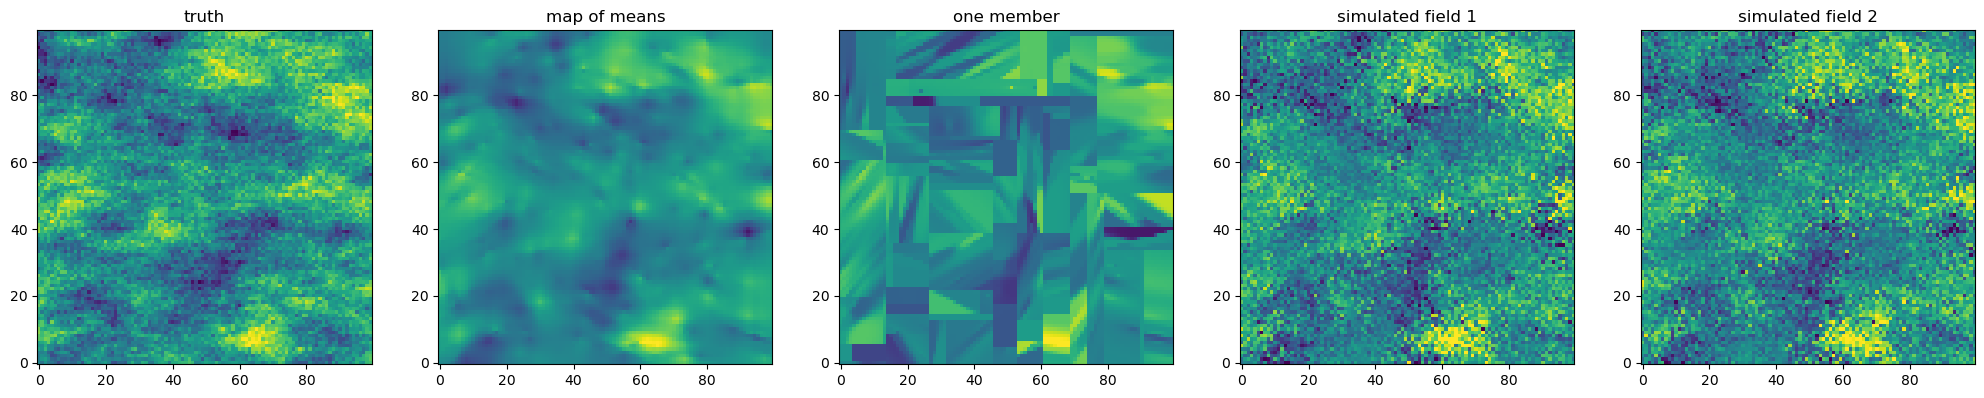

In [2]:
def simulate(factory, n_sims=100):
    start = time.perf_counter()
    fields = np.asarray(ess_sample(result, n_sims=n_sims, fitted_model_factory=factory, callback=quiet).scenarios)
    return fields.reshape(*truth.shape, -1), time.perf_counter() - start

fields, seconds = simulate(FittedModelFactory(widening="skew_normal", seed=0))
print(f"100 fields at {truth.size} locations in {seconds:.0f} s")

panels = [("truth", truth), ("map of means", members.mean(axis=-1)), ("one member", members[..., 0]),
          ("simulated field 1", fields[..., 0]), ("simulated field 2", fields[..., 1])]
fig, axes = plt.subplots(1, 5, figsize=(25, 4.6))
for ax, (title, z) in zip(axes, panels):
    ax.imshow(z.T, origin="lower", cmap="viridis", vmin=-2.5, vmax=2.5)
    ax.set_title(title)
plt.show()

The 100 fields take a few seconds. Each simulated field shows the large features of the truth in
their places, the high patches near the top and at the bottom, the low band through the middle, with a
grain at the shortest range that the truth does not have. The map of means is smooth, while a member shows
the cells of its partition.

### The geometry kept, the geometry lost

The experimental variogram, half the mean squared difference between values a given distance apart,
describes the geometry of a field. We compute it along each axis for the truth, the simulated fields, the
members and the map of means.

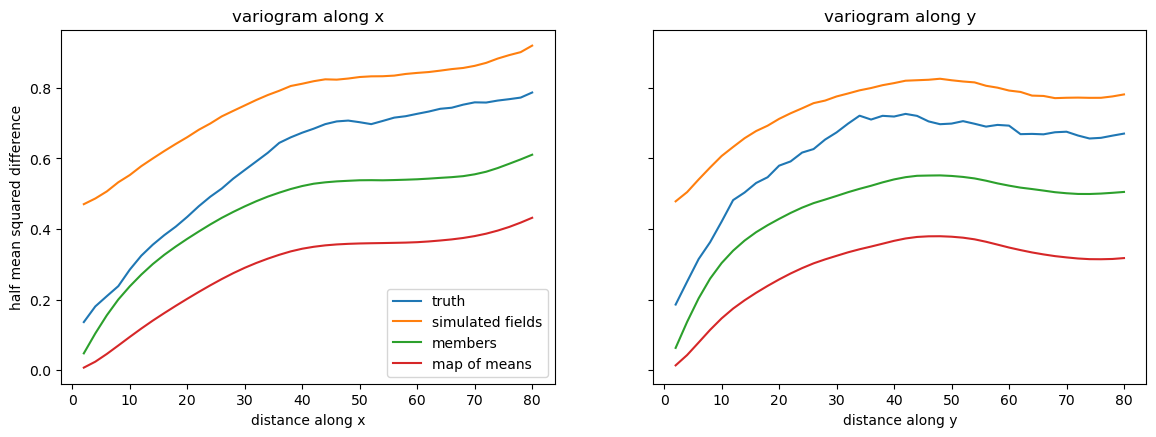

,"at distance 2, along x","at distance 40, along x","at distance 2, along y","at distance 40, along y"
truth,0.136,0.673,0.186,0.719
simulated fields,0.470,0.812,0.478,0.814
members,0.048,0.522,0.063,0.541
map of means,0.007,0.344,0.013,0.367


In [3]:
def variogram(z, axis, lags):
    # z[..., k] fields on the grid; half the mean squared difference at each lag along one axis
    z = z if z.ndim == 3 else z[..., None]
    return np.array([0.5 * np.mean((np.take(z, range(h, z.shape[axis]), axis=axis) -
                                    np.take(z, range(0, z.shape[axis] - h), axis=axis)) ** 2) for h in lags])

lags = np.arange(1, 41)
curves = {"truth": truth, "simulated fields": fields[..., :20], "members": members[..., :20], "map of means": members.mean(axis=-1)}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, axis, name in zip(axes, (0, 1), ("along x", "along y")):
    for label, z in curves.items():
        ax.plot(2 * lags, variogram(z, axis, lags), label=label)
    ax.set_xlabel(f"distance {name}"); ax.set_title(f"variogram {name}")
axes[0].set_ylabel("half mean squared difference"); axes[0].legend()
plt.show()
pd.DataFrame({label: {"at distance 2, along x": variogram(z, 0, [1])[0], "at distance 40, along x": variogram(z, 0, [20])[0],
                      "at distance 2, along y": variogram(z, 1, [1])[0], "at distance 40, along y": variogram(z, 1, [20])[0]}
              for label, z in curves.items()}).T.round(3)

The simulated fields keep the shape of the truth's variogram beyond the shortest distances, rising
faster along y than along x, as the field's correlation does, and levelling off at about the same
distances. Their curve starts higher, at 0.47 against 0.14 at the first distance, the nugget of the
independent draws, and stays above the truth's by that much, so they carry more variance than the field.
The members and the map of means start low, too smooth at short range, the map of means levelling off
at half the truth's variance.

### The local models

The local law can be a kernel density (`point_model_name="kde"`, the default), a Gaussian mixture fitted
by expectation–maximisation (`"emm"`), or either of them widened. We compare the laws by the coverage of
their 90 % interval and by the CRPS against the truth, a score of the whole law, lower being better.

In [4]:
def crps(sample, y):
    # the exact CRPS of the sample's empirical law at each location, E|X - y| - E|X - X'| / 2
    x = np.sort(sample.reshape(-1, sample.shape[-1]), axis=1)
    n = x.shape[1]
    spread = (2 * np.arange(1, n + 1) - n - 1) @ x.T / n ** 2
    return np.mean(np.abs(x - y.reshape(-1, 1)).mean(axis=1) - spread)

def coverage(sample):
    low, high = np.percentile(sample, [5, 95], axis=-1)
    return np.mean((low <= truth) & (truth <= high))

laws = {"members": (members, 0.0)}
for name, factory in (("kernel density", FittedModelFactory(seed=0)),
                      ("Gaussian mixture", FittedModelFactory(point_model_name="emm", seed=0)),
                      ("kernel density, widened", FittedModelFactory(widening="skew_normal", seed=0))):
    laws[name] = (fields, seconds) if name == "kernel density, widened" else simulate(factory)
pd.DataFrame({name: {"90 % coverage": coverage(s), "CRPS": crps(s, truth), "seconds": t}
              for name, (s, t) in laws.items()}).T.round(3)

,90 % coverage,CRPS,seconds
members,0.644,0.353,0.000
kernel density,0.664,0.351,0.217
Gaussian mixture,0.651,0.352,1.712
"kernel density, widened",0.896,0.334,3.225


The kernel density and the Gaussian mixture follow the members closely, covering 66 % and 65 %, since
they smooth the same narrow sample. The widened law covers 89.6 %, close to the nominal 90 %, with the
best CRPS, 0.334 against 0.351 to 0.353. The Gaussian mixture takes about eight times as long as the kernel density without a better law.

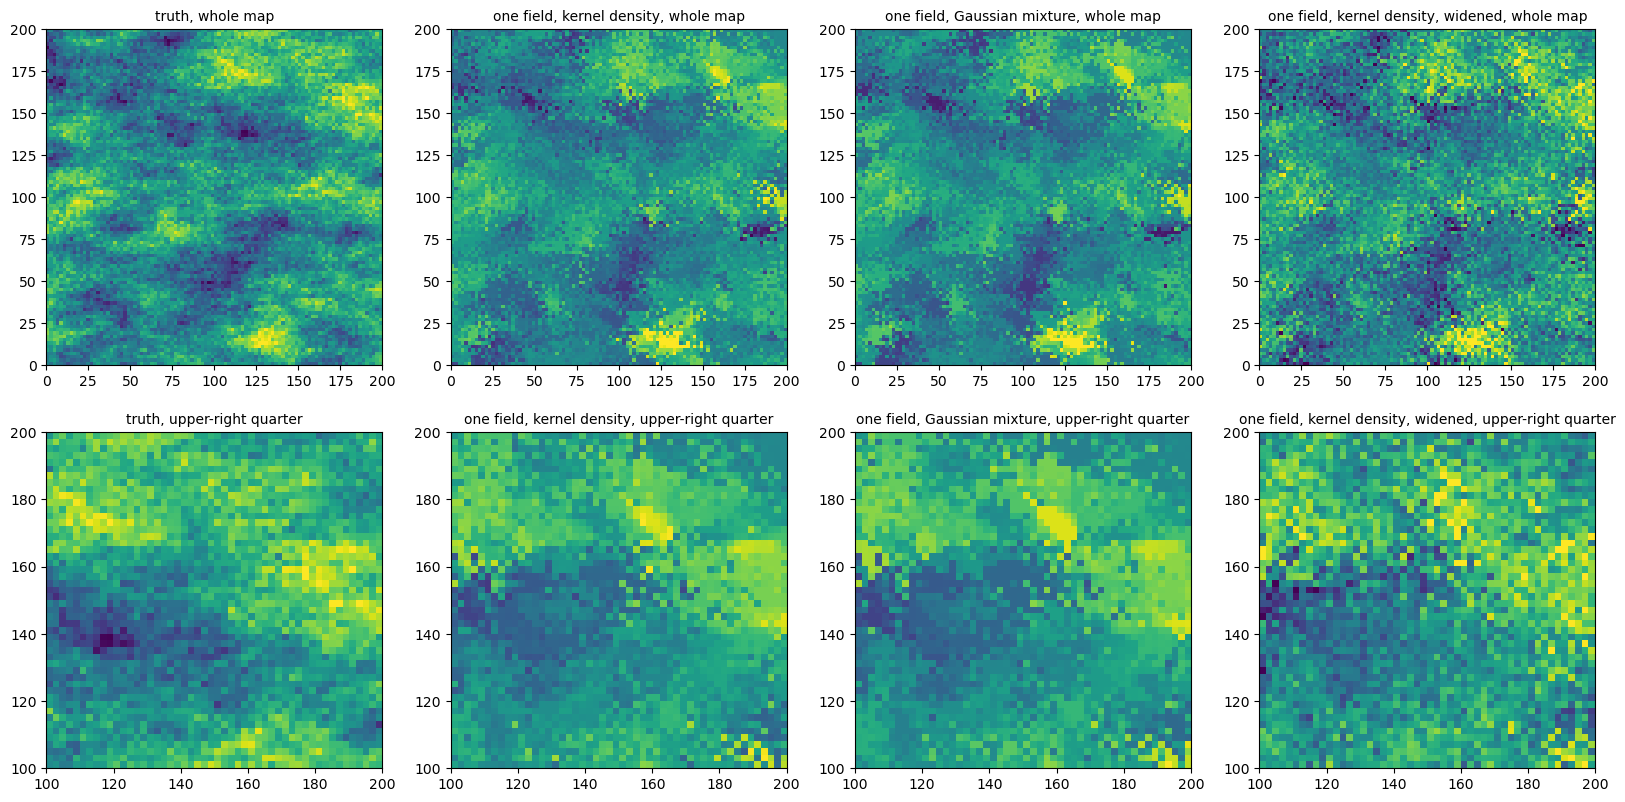

In [5]:
models = ["kernel density", "Gaussian mixture", "kernel density, widened"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9.6))
for row, (sl, where) in enumerate(((np.s_[:, :], "whole map"), (np.s_[50:, 50:], "upper-right quarter"))):
    extent = (0, 200, 0, 200) if row == 0 else (100, 200, 100, 200)
    panels = [("truth", truth)] + [(name, laws[name][0][..., 0]) for name in models]
    for ax, (title, z) in zip(axes[row], panels):
        ax.imshow(z[sl].T, origin="lower", cmap="viridis", vmin=-2.5, vmax=2.5, extent=extent)
        ax.set_title(f"{title}, {where}" if title == "truth" else f"one field, {title}, {where}", fontsize=10)
plt.show()

A field drawn from the kernel density and one drawn from the Gaussian mixture look alike, since both
laws smooth the same members. Their values stay close to the map of means, with the large patches of the
truth and little grain. Drawn from the widened law, a field spreads as far as the data do, so its high
and low values reach the truth's while its grain at short range is coarser than the truth's. The upper
right quarter shows it best, where the truth varies smoothly and the widened field scatters around the
same pattern.

### One location against the whole map

The simulated fields answer a question about one location as well as the local law does, since they
sample it. A question about the whole map is another matter. The share of the map above 1 varies from one field to the next. A total or an area needs the spread of that share.

In [6]:
share = lambda z: np.mean(z > 1.0, axis=(0, 1))
pd.DataFrame({"truth": {"share of the map above 1": np.mean(truth > 1.0)},
              "simulated fields": {"share of the map above 1": share(fields).mean(), "spread across fields": share(fields).std()},
              "members": {"share of the map above 1": share(members).mean(), "spread across fields": share(members).std()}}).T.round(4)

,share of the map above 1,spread across fields
truth,0.1414,NaN
simulated fields,0.1447,0.0029
members,0.1107,0.0108


The simulated fields put 14.5 % of the map above 1, close to the truth's 14.1 %. That share barely moves between fields, a spread of 0.3 percentage points. The members, read as fields, spread four times
more, 1.1 points, while placing the share lower, at 11.1 %, since each member is smoother than the
field. Neither gives a calibrated law of the share on its own. The spread of the simulated fields comes
only from drawing thousands of locations independently, so it would shrink further on a finer grid.

## Pitfalls

- **An area or a total from the simulated fields.** Their draws are independent between locations, so
  the spread of any sum over the map shrinks with the number of locations. Read such questions from the
  members of a drawing decoder, as the tutorial on exceedance areas does. The members of an averaging
  decoder are smoother than the field, which shifts a share above a threshold.
- **The roughness of a simulated field taken as the field's.** At the shortest distances the draws
  scatter like a nugget. Read the short-range behaviour from the data, not from a simulated field.
- **The number of fields.** `n_sims` is the total number of fields, each drawn at every location.
- **Simulation without a seed.** The draws are random. Give `FittedModelFactory` a `seed` for
  reproducible fields.
- **Widening without the data.** The widened law needs the data the result was computed from, which
  results from `esi_griddata` and `esi_nongriddata` carry.

## Try it yourself

1. Simulate from a drawing decoder (`local_interpolator="wdraw_sharpidw"`) without widening and compare
   its coverage with the widened law's.
2. Compute the variogram of the simulated fields along the diagonal at 30°, the direction of the field.
3. Fit the local laws with `"vim"`, the variational mixture, and compare its time.

## Next

- *Uncertainty at a location*, for the fitted laws and their widening.
- *Exceedance areas*, for a whole-map question answered by the members.
- *The probabilistic decoders*, for members that carry the spread of the data.
- The documentation's [Ensemble spatial simulation](https://spatialize.readthedocs.io/en/latest/theory/ess.html)
  (theory) and [ESS reference](https://spatialize.readthedocs.io/en/latest/reference/ess.html).